# Analisis Benchmarking Performa Pandas, Polars, dan Dask

**Mata Kuliah:** Desain dan Arsitektur Aplikasi Big Data (DABD)

## 1. Tujuan Analisis

Notebook ini bertujuan untuk:

1. Menganalisis dan membandingkan performa *runtime* Pandas, Polars, dan Dask pada berbagai
   ukuran dataset dan jenis operasi.
2. Mengevaluasi konsistensi dan variabilitas hasil pengukuran melalui pengulangan eksperimen.
3. Menganalisis penggunaan memori dan CPU pada masing-masing pustaka, sejauh data yang tersedia
   memungkinkan.
4. Memeriksa validitas dan konsistensi output antar pustaka.
5. Merangkum temuan dalam bentuk tabel perbandingan serta menarik kesimpulan yang **didukung oleh
   data aktual**, bukan asumsi.

## 2. Library yang Dibandingkan

| Pustaka | Karakteristik Utama |
|---|---|
| **Pandas** | Pemrosesan data *in-memory*, *single-threaded*, API paling matang dan luas digunakan. |
| **Polars** | Mesin eksekusi berbasis Rust, mendukung eksekusi paralel dan *lazy evaluation*. |
| **Dask** | Pemrosesan data terdistribusi/paralel berbasis *task graph* dan *partitioning*. |

## 3. Operasi yang Diuji

Berdasarkan data hasil benchmark yang tersedia, operasi yang diuji mencakup:

- **Read** membaca dataset sumber.
- **Filter** menyaring baris berdasarkan kondisi tertentu.
- **Aggregation** agregasi sederhana pada suatu kolom.
- **Group By** pengelompokan data disertai agregasi.

## 4. Ukuran Dataset

Eksperimen dirancang untuk tiga skala ukuran dataset, yaitu **100 ribu (100k)**,
**1 juta (1m)**, dan **5 juta (5m)** baris. Ukuran aktual dataset akan diverifikasi langsung dari
data pada Bagian 4, karena label ukuran tidak selalu identik dengan jumlah baris riil yang
diproses (misalnya jika sumber data telah dibatasi jumlah barisnya).

## 5. Sumber Data

Notebook ini **tidak menjalankan ulang proses benchmarking** dan **tidak membaca dataset Parquet
sumber**. Seluruh analisis murni didasarkan pada dua berkas hasil yang telah diproses sebelumnya:

- `results/processed/benchmark_summary.csv` — hasil mentah per pengulangan (*per-repeat*).
- `results/processed/benchmark_comparison.csv` — hasil agregat (*mean*, *std*, *min*, *max*) per
  kombinasi pustaka, operasi, dan ukuran dataset.

Setiap metrik yang dianalisis (*runtime*, memori, CPU, validasi output) hanya akan dibahas apabila
kolom terkait benar-benar tersedia dan nilainya dapat dipercaya pada berkas tersebut.


## Bagian 2 Import Library dan Konfigurasi

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Seaborn bersifat opsional; jika tidak tersedia, notebook tetap berjalan
# menggunakan matplotlib murni.
try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False
    warnings.warn(
        "Seaborn tidak ditemukan pada environment ini. Visualisasi akan "
        "menggunakan matplotlib murni sebagai gantinya."
    )

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

if HAS_SEABORN:
    sns.set_theme(style="whitegrid", palette="deep")
else:
    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.autolayout": False,
})

# Urutan kategori standar yang dipakai berulang kali di seluruh notebook.
TOOL_ORDER = ["pandas", "polars", "dask"]
SIZE_ORDER = ["100k", "1m", "5m"]
OP_ORDER = ["read", "filter", "aggregation", "group_by"]

TOOL_COLORS = dict(zip(TOOL_ORDER, sns.color_palette("deep", 3) if HAS_SEABORN
                        else plt.cm.tab10.colors[:3]))

print("Konfigurasi selesai. Seaborn tersedia:", HAS_SEABORN)

Konfigurasi selesai. Seaborn tersedia: True


## Bagian 3 Membaca Data

In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_DIR = PROJECT_ROOT / "results" / "processed"

SUMMARY_PATH = DATA_DIR / "benchmark_summary.csv"
COMPARISON_PATH = DATA_DIR / "benchmark_comparison.csv"

def load_csv_or_fail(path: Path) -> pd.DataFrame:
    '''Membaca CSV dengan pesan kesalahan yang jelas apabila berkas tidak ditemukan.'''
    if not path.exists():
        raise FileNotFoundError(
            f"Berkas data tidak ditemukan di: {path}\n"
            f"Pastikan notebook dijalankan dari folder 'notebooks/' pada struktur "
            f"proyek berikut:\n"
            f"  <root_proyek>/results/processed/{path.name}\n"
            f"  <root_proyek>/notebooks/benchmark.ipynb\n"
            f"Direktori kerja saat ini terdeteksi sebagai: {NOTEBOOK_DIR}"
        )
    return pd.read_csv(path)

df_summary = load_csv_or_fail(SUMMARY_PATH)
df_comparison = load_csv_or_fail(COMPARISON_PATH)

print(f"benchmark_summary.csv berhasil dibaca dari: {SUMMARY_PATH}")
print(f"benchmark_comparison.csv berhasil dibaca dari: {COMPARISON_PATH}")

benchmark_summary.csv berhasil dibaca dari: /workspace/results/processed/benchmark_summary.csv
benchmark_comparison.csv berhasil dibaca dari: /workspace/results/processed/benchmark_comparison.csv


In [3]:
print("=== benchmark_summary.csv ===")
print("Dimensi (baris, kolom):", df_summary.shape)
print("\nNama kolom dan tipe data:")
print(df_summary.dtypes)
print("\n5 baris pertama:")
display(df_summary.head())

=== benchmark_summary.csv ===
Dimensi (baris, kolom): (180, 10)

Nama kolom dan tipe data:
tool                   str
operation              str
dataset_size           str
repeat               int64
runtime_seconds    float64
memory_mb          float64
cpu_percent        float64
output_rows          int64
validated             bool
detail                 str
dtype: object

5 baris pertama:


,tool,operation,dataset_size,repeat,runtime_seconds,memory_mb,cpu_percent,output_rows,validated,detail
0,pandas,read,100k,1,5.835188,"1,359.917969",0.000000,100000,True,read parquet and take first N rows
1,pandas,filter,100k,1,0.006354,"1,378.667969",0.000000,1780,True,VendorID > median
2,pandas,aggregation,100k,1,0.000431,"1,378.792969",1.200000,1,True,sum(VendorID)
3,pandas,group_by,100k,1,0.003120,"1,379.417969",0.000000,7,True,"group by passenger_count, sum(VendorID)"
4,pandas,read,100k,2,2.490192,86.363281,1.300000,100000,True,read parquet and take first N rows


In [4]:
print("=== benchmark_comparison.csv ===")
print("Dimensi (baris, kolom):", df_comparison.shape)
print("\nNama kolom dan tipe data:")
print(df_comparison.dtypes)
print("\n5 baris pertama:")
display(df_comparison.head())

=== benchmark_comparison.csv ===
Dimensi (baris, kolom): (36, 7)

Nama kolom dan tipe data:
tool                str
operation           str
dataset_size        str
mean            float64
std             float64
min             float64
max             float64
dtype: object

5 baris pertama:


,tool,operation,dataset_size,mean,std,min,max
0,dask,aggregation,100k,0.000472,0.000247,0.000337,0.000912
1,dask,aggregation,1m,0.000804,0.000195,0.000613,0.001119
2,dask,aggregation,5m,0.001963,0.000162,0.001787,0.002119
3,dask,filter,100k,0.003953,0.002338,0.002680,0.008122
4,dask,filter,1m,0.025582,0.011515,0.016176,0.043737


In [5]:
print("=== Informasi nilai kosong (missing values) ===\n")
print("benchmark_summary.csv:")
print(df_summary.isnull().sum())
print("\nbenchmark_comparison.csv:")
print(df_comparison.isnull().sum())

=== Informasi nilai kosong (missing values) ===

benchmark_summary.csv:
tool               0
operation          0
dataset_size       0
repeat             0
runtime_seconds    0
memory_mb          0
cpu_percent        0
output_rows        0
validated          0
detail             0
dtype: int64

benchmark_comparison.csv:
tool            0
operation       0
dataset_size    0
mean            0
std             0
min             0
max             0
dtype: int64


In [6]:
print("=== Statistik deskriptif kolom numerik ===\n")
print("benchmark_summary.csv (kolom numerik relevan):")
numeric_cols_summary = [c for c in ["runtime_seconds", "memory_mb", "cpu_percent", "output_rows", "repeat"]
                         if c in df_summary.columns]
display(df_summary[numeric_cols_summary].describe())

print("\nbenchmark_comparison.csv (kolom numerik relevan):")
numeric_cols_comparison = [c for c in ["mean", "std", "min", "max"] if c in df_comparison.columns]
display(df_comparison[numeric_cols_comparison].describe())

=== Statistik deskriptif kolom numerik ===

benchmark_summary.csv (kolom numerik relevan):


,runtime_seconds,memory_mb,cpu_percent,output_rows,repeat
count,180.000000,180.000000,180.000000,180.000000,180.000000
mean,0.525232,"1,040.112934",1.691111,"391,447.333333",3.000000
std,1.022132,539.005424,5.807905,"987,446.642460",1.418158
min,0.000337,0.000000,0.000000,1.000000,1.000000
25%,0.002109,754.592773,0.000000,5.500000,2.000000
50%,0.018987,"1,026.464844",0.600000,894.000000,3.000000
75%,0.617954,"1,465.781250",1.200000,"62,144.500000",4.000000
max,5.835188,"2,061.324219",44.800000,"3,530,109.000000",5.000000



benchmark_comparison.csv (kolom numerik relevan):


,mean,std,min,max
count,36.000000,36.000000,36.000000,36.000000
mean,0.525232,0.171085,0.380761,0.792106
std,0.958430,0.396799,0.717072,1.522116
min,0.000435,0.000056,0.000337,0.000548
25%,0.002453,0.000447,0.001904,0.003442
50%,0.019035,0.003240,0.015077,0.027542
75%,0.482966,0.151616,0.257394,0.799912
max,3.160694,1.737096,2.588962,5.835188


## Bagian 4 Data Understanding dan Validasi (EDA)

Sebelum melakukan analisis lebih lanjut, bagian ini memverifikasi struktur dan kualitas data secara
eksplisit.

In [7]:
issues = []  # menampung catatan/peringatan yang ditemukan selama validasi

# --- 1. Ketersediaan tiga tools ---
found_tools = set(df_summary["tool"].unique())
expected_tools = {"pandas", "polars", "dask"}
print("Tools ditemukan pada data:", sorted(found_tools))
if found_tools != expected_tools:
    msg = f"Tools tidak sesuai ekspektasi. Ditemukan: {found_tools}, diharapkan: {expected_tools}"
    issues.append(msg)
    warnings.warn(msg)
else:
    print("-> Ketiga tools (pandas, polars, dask) tersedia lengkap.")

Tools ditemukan pada data: ['dask', 'pandas', 'polars']
-> Ketiga tools (pandas, polars, dask) tersedia lengkap.


In [8]:
# --- 2. Ketersediaan empat operasi ---
found_ops = set(df_summary["operation"].unique())
expected_ops = {"read", "filter", "aggregation", "group_by"}
print("Operasi ditemukan pada data:", sorted(found_ops))
if found_ops != expected_ops:
    msg = f"Operasi tidak sesuai ekspektasi. Ditemukan: {found_ops}, diharapkan: {expected_ops}"
    issues.append(msg)
    warnings.warn(msg)
else:
    print("-> Keempat operasi (read, filter, aggregation, group_by) tersedia lengkap.")

Operasi ditemukan pada data: ['aggregation', 'filter', 'group_by', 'read']
-> Keempat operasi (read, filter, aggregation, group_by) tersedia lengkap.


In [9]:
# --- 3. Ukuran dataset: label vs jumlah baris aktual ---
# Label ukuran dataset ('100k', '1m', '5m') adalah label nominal pada eksperimen
found_sizes = set(df_summary["dataset_size"].unique())
expected_sizes = {"100k", "1m", "5m"}
print("Label ukuran dataset ditemukan:", sorted(found_sizes))

actual_rows_per_size = (
    df_summary[df_summary["operation"] == "read"]
    .groupby("dataset_size")["output_rows"]
    .unique()
)
print("\nJumlah baris AKTUAL (dari output_rows operasi 'read') per label ukuran dataset:")
print(actual_rows_per_size)

nominal_map = {"100k": 100_000, "1m": 1_000_000, "5m": 5_000_000}
for size_label, rows_arr in actual_rows_per_size.items():
    actual = rows_arr[0] if len(rows_arr) == 1 else rows_arr
    nominal = nominal_map.get(size_label)
    if isinstance(actual, (int, np.integer)) and nominal is not None and actual != nominal:
        msg = (
            f"Label dataset '{size_label}' bernilai nominal {nominal:,} baris, "
            f"namun jumlah baris aktual yang terekam adalah {actual:,} baris. "
            f"Kemungkinan sumber data dibatasi oleh ukuran berkas asli. "
            f"Seluruh analisis pada notebook ini tetap menggunakan LABEL '{size_label}' "
            f"sebagaimana tercatat di data, namun perbedaan ini perlu diperhatikan saat "
            f"menafsirkan hasil 'read'."
        )
        issues.append(msg)
        warnings.warn(msg)

Label ukuran dataset ditemukan: ['100k', '1m', '5m']

Jumlah baris AKTUAL (dari output_rows operasi 'read') per label ukuran dataset:
dataset_size
100k     [100000]
1m      [1000000]
5m      [3530109]
Name: output_rows, dtype: object


/tmp/ipykernel_178/4179907164.py:29: UserWarning: Label dataset '5m' bernilai nominal 5,000,000 baris, namun jumlah baris aktual yang terekam adalah 3,530,109 baris. Kemungkinan sumber data dibatasi oleh ukuran berkas asli. Seluruh analisis pada notebook ini tetap menggunakan LABEL '5m' sebagaimana tercatat di data, namun perbedaan ini perlu diperhatikan saat menafsirkan hasil 'read'.
  warnings.warn(msg)


In [10]:
# --- 4. Nilai kosong pada kolom penting ---
important_cols = ["tool", "operation", "dataset_size", "runtime_seconds"]
important_cols = [c for c in important_cols if c in df_summary.columns]
null_counts = df_summary[important_cols].isnull().sum()
print("Nilai kosong pada kolom penting (benchmark_summary.csv):")
print(null_counts)
if null_counts.sum() > 0:
    msg = f"Ditemukan nilai kosong pada kolom penting: {null_counts[null_counts > 0].to_dict()}"
    issues.append(msg)
    warnings.warn(msg)
else:
    print("-> Tidak ada nilai kosong pada kolom penting.")

Nilai kosong pada kolom penting (benchmark_summary.csv):
tool               0
operation          0
dataset_size       0
runtime_seconds    0
dtype: int64
-> Tidak ada nilai kosong pada kolom penting.


In [11]:
# --- 5. Validitas kolom runtime (harus numerik dan non-negatif) ---
runtime_negative = (df_summary["runtime_seconds"] < 0).sum()
runtime_nan = df_summary["runtime_seconds"].isnull().sum()
print(f"Jumlah nilai runtime negatif: {runtime_negative}")
print(f"Jumlah nilai runtime kosong/NaN: {runtime_nan}")
if runtime_negative > 0 or runtime_nan > 0:
    msg = f"Ditemukan runtime tidak valid: {runtime_negative} negatif, {runtime_nan} kosong."
    issues.append(msg)
    warnings.warn(msg)
else:
    print("-> Seluruh nilai runtime_seconds valid (numerik dan non-negatif).")

Jumlah nilai runtime negatif: 0
Jumlah nilai runtime kosong/NaN: 0
-> Seluruh nilai runtime_seconds valid (numerik dan non-negatif).


In [12]:
# --- 6. Duplikasi dan konsistensi jumlah pengulangan ---
dup_key = ["tool", "operation", "dataset_size", "repeat"]
n_duplicates = df_summary.duplicated(subset=dup_key).sum()
print(f"Jumlah baris duplikat (kombinasi {dup_key}): {n_duplicates}")
if n_duplicates > 0:
    msg = f"Ditemukan {n_duplicates} baris duplikat pada kombinasi {dup_key}."
    issues.append(msg)
    warnings.warn(msg)

repeat_counts = df_summary.groupby(["tool", "operation", "dataset_size"])["repeat"].count()
unique_repeat_counts = repeat_counts.unique()
print(f"\nJumlah pengulangan per kombinasi (tool, operation, dataset_size): {sorted(unique_repeat_counts)}")
if len(unique_repeat_counts) == 1:
    print(f"-> Seluruh kombinasi memiliki {unique_repeat_counts[0]} kali pengulangan yang konsisten.")
else:
    msg = f"Jumlah pengulangan TIDAK konsisten antar kombinasi: {sorted(unique_repeat_counts)}"
    issues.append(msg)
    warnings.warn(msg)
    print("Kombinasi dengan jumlah pengulangan tidak standar:")
    display(repeat_counts[repeat_counts != repeat_counts.mode()[0]])

Jumlah baris duplikat (kombinasi ['tool', 'operation', 'dataset_size', 'repeat']): 0

Jumlah pengulangan per kombinasi (tool, operation, dataset_size): [np.int64(5)]
-> Seluruh kombinasi memiliki 5 kali pengulangan yang konsisten.


In [13]:
# --- 7. Cross-check: benchmark_comparison.csv vs rekalkulasi dari benchmark_summary.csv ---
# Tujuannya untuk memverifikasi bahwa berkas agregat (comparison) memang konsisten
# dengan data mentah per-repeat (summary), bukan berkas terpisah yang tidak selaras.
recalculated = (
    df_summary.groupby(["tool", "operation", "dataset_size"])["runtime_seconds"]
    .agg(mean="mean", std="std", min="min", max="max")
    .reset_index()
)
cross_check = df_comparison.merge(
    recalculated, on=["tool", "operation", "dataset_size"], suffixes=("_file", "_recalc")
)
cross_check["mean_abs_diff"] = (cross_check["mean_file"] - cross_check["mean_recalc"]).abs()
max_diff = cross_check["mean_abs_diff"].max()

print(f"Selisih absolut maksimum antara 'mean' pada benchmark_comparison.csv dan hasil "
      f"rekalkulasi dari benchmark_summary.csv: {max_diff:.2e}")
if max_diff < 1e-9:
    print("-> benchmark_comparison.csv KONSISTEN dengan benchmark_summary.csv "
          "(selisih dapat diabaikan / floating-point rounding).")
else:
    msg = f"benchmark_comparison.csv TIDAK konsisten dengan rekalkulasi dari benchmark_summary.csv (selisih max={max_diff:.4f})."
    issues.append(msg)
    warnings.warn(msg)

Selisih absolut maksimum antara 'mean' pada benchmark_comparison.csv dan hasil rekalkulasi dari benchmark_summary.csv: 8.07e-17
-> benchmark_comparison.csv KONSISTEN dengan benchmark_summary.csv (selisih dapat diabaikan / floating-point rounding).


In [14]:
# --- 8. Anomali pada kolom memory_mb dan cpu_percent ---
zero_memory = df_summary[df_summary["memory_mb"] == 0]
zero_cpu_pct = (df_summary["cpu_percent"] == 0).mean() * 100

print(f"Jumlah baris dengan memory_mb == 0: {len(zero_memory)} dari {len(df_summary)} baris")
if len(zero_memory) > 0:
    msg = (
        f"Ditemukan {len(zero_memory)} baris dengan memory_mb = 0, yang secara fisik tidak "
        f"masuk akal untuk proses Python yang sedang berjalan. Ini kemungkinan besar merupakan "
        f"ARTEFAK PENGUKURAN (misalnya pembacaan memori pada waktu yang tidak tepat), bukan "
        f"nilai penggunaan memori yang valid. Baris-baris ini akan diberi catatan khusus pada "
        f"analisis memori (Bagian 7) dan TIDAK dihapus dari data, hanya dikecualikan secara "
        f"eksplisit dari perhitungan rata-rata memori agar tidak mendistorsi hasil."
    )
    issues.append(msg)
    warnings.warn(msg)
    display(zero_memory[["tool", "operation", "dataset_size", "repeat", "memory_mb"]])

print(f"\nProporsi baris dengan cpu_percent == 0: {zero_cpu_pct:.1f}%")
if zero_cpu_pct > 20:
    msg = (
        f"Sebanyak {zero_cpu_pct:.1f}% baris memiliki cpu_percent = 0. Perilaku ini umum terjadi "
        f"pada pustaka pengukuran CPU (mis. psutil) yang mengembalikan 0.0 pada pemanggilan "
        f"pertama atau saat interval pengukuran sangat singkat. Proporsi ini terlalu tinggi untuk "
        f"dijadikan dasar perbandingan CPU yang valid antar tools, sehingga analisis CPU pada "
        f"Bagian 7 akan bersifat deskriptif dan disertai peringatan keterbatasan, bukan klaim "
        f"perbandingan definitif."
    )
    issues.append(msg)
    warnings.warn(msg)

Jumlah baris dengan memory_mb == 0: 5 dari 180 baris


/tmp/ipykernel_178/3804310401.py:16: UserWarning: Ditemukan 5 baris dengan memory_mb = 0, yang secara fisik tidak masuk akal untuk proses Python yang sedang berjalan. Ini kemungkinan besar merupakan ARTEFAK PENGUKURAN (misalnya pembacaan memori pada waktu yang tidak tepat), bukan nilai penggunaan memori yang valid. Baris-baris ini akan diberi catatan khusus pada analisis memori (Bagian 7) dan TIDAK dihapus dari data, hanya dikecualikan secara eksplisit dari perhitungan rata-rata memori agar tidak mendistorsi hasil.
  warnings.warn(msg)


,tool,operation,dataset_size,repeat,memory_mb
8,pandas,read,100k,3,0.000000
12,pandas,read,100k,4,0.000000
108,polars,read,5m,3,0.000000
132,dask,read,100k,4,0.000000
156,dask,read,1m,5,0.000000



Proporsi baris dengan cpu_percent == 0: 47.8%


/tmp/ipykernel_178/3804310401.py:30: UserWarning: Sebanyak 47.8% baris memiliki cpu_percent = 0. Perilaku ini umum terjadi pada pustaka pengukuran CPU (mis. psutil) yang mengembalikan 0.0 pada pemanggilan pertama atau saat interval pengukuran sangat singkat. Proporsi ini terlalu tinggi untuk dijadikan dasar perbandingan CPU yang valid antar tools, sehingga analisis CPU pada Bagian 7 akan bersifat deskriptif dan disertai peringatan keterbatasan, bukan klaim perbandingan definitif.
  warnings.warn(msg)


In [15]:
# --- 9. Ringkasan seluruh temuan validasi ---
print("=" * 70)
print(f"RINGKASAN VALIDASI: {len(issues)} catatan/peringatan ditemukan")
print("=" * 70)
if issues:
    for i, msg in enumerate(issues, 1):
        print(f"\n[{i}] {msg}")
else:
    print("Tidak ditemukan masalah data yang signifikan.")

RINGKASAN VALIDASI: 3 catatan/peringatan ditemukan

[1] Label dataset '5m' bernilai nominal 5,000,000 baris, namun jumlah baris aktual yang terekam adalah 3,530,109 baris. Kemungkinan sumber data dibatasi oleh ukuran berkas asli. Seluruh analisis pada notebook ini tetap menggunakan LABEL '5m' sebagaimana tercatat di data, namun perbedaan ini perlu diperhatikan saat menafsirkan hasil 'read'.

[2] Ditemukan 5 baris dengan memory_mb = 0, yang secara fisik tidak masuk akal untuk proses Python yang sedang berjalan. Ini kemungkinan besar merupakan ARTEFAK PENGUKURAN (misalnya pembacaan memori pada waktu yang tidak tepat), bukan nilai penggunaan memori yang valid. Baris-baris ini akan diberi catatan khusus pada analisis memori (Bagian 7) dan TIDAK dihapus dari data, hanya dikecualikan secara eksplisit dari perhitungan rata-rata memori agar tidak mendistorsi hasil.

[3] Sebanyak 47.8% baris memiliki cpu_percent = 0. Perilaku ini umum terjadi pada pustaka pengukuran CPU (mis. psutil) yang menge

**Catatan interpretasi Bagian 4:** Validasi di atas mengonfirmasi bahwa struktur data secara
umum lengkap dan konsisten (tiga tools, empat operasi, tanpa duplikasi, tanpa nilai kosong pada
kolom penting, dan `benchmark_comparison.csv` selaras dengan `benchmark_summary.csv`). Namun,
ditemukan dua keterbatasan pengukuran yang perlu diperhatikan sepanjang notebook ini: **(a)** label
ukuran dataset `5m` pada operasi *read* ternyata berkorespondensi dengan jumlah baris aktual yang
berbeda dari 5.000.000 (kemungkinan dibatasi oleh ukuran berkas sumber), dan **(b)** sebagian nilai
`memory_mb` dan `cpu_percent` mengindikasikan artefak pengukuran. Kedua hal ini akan ditangani
secara eksplisit, bukan diabaikan, pada bagian-bagian analisis selanjutnya.

## Bagian 5 Analisis Runtime

Analisis pada bagian ini menggunakan `benchmark_comparison.csv` sebagai sumber utama, karena berkas tersebut sudah berisi statistik agregat (*mean*, *std*) hasil dari 5 kali pengulangan untuk setiap kombinasi pustaka × operasi × ukuran dataset.

Perlu digarisbawahi bahwa keempat operasi memiliki **orde besar (*magnitude*) waktu yang sangat berbeda**: operasi *read* berlangsung pada skala **detik**, sedangkan *filter*, *aggregation*, dan *group by* berlangsung pada skala **milidetik**. Oleh karena itu, operasi *read* akan divisualisasikan secara terpisah dari ketiga operasi lainnya agar perbandingan tetap bermakna dan tidak "tenggelam" akibat perbedaan skala.

In [16]:
def prep_comparison(df):
    '''Menyalin dan mengurutkan comparison df sesuai urutan kategori standar.'''
    out = df.copy()
    out["dataset_size"] = pd.Categorical(out["dataset_size"], categories=SIZE_ORDER, ordered=True)
    out["tool"] = pd.Categorical(out["tool"], categories=TOOL_ORDER, ordered=True)
    out["operation"] = pd.Categorical(out["operation"], categories=OP_ORDER, ordered=True)
    return out.sort_values(["operation", "dataset_size", "tool"])

def grouped_bar(ax, data, x_col, hue_col, y_col, err_col=None, order=None, hue_order=None, title="", ylabel=""):
    '''Helper generik untuk bar chart berkelompok dengan optional error bar.'''
    order = order or sorted(data[x_col].unique())
    hue_order = hue_order or sorted(data[hue_col].unique())
    n_hue = len(hue_order)
    width = 0.8 / n_hue
    x_pos = np.arange(len(order))

    for i, hue_val in enumerate(hue_order):
        sub = data[data[hue_col] == hue_val].set_index(x_col).reindex(order)
        vals = sub[y_col].values
        errs = sub[err_col].values if err_col else None
        offset = (i - (n_hue - 1) / 2) * width
        ax.bar(x_pos + offset, vals, width=width, yerr=errs, capsize=3,
               label=str(hue_val), color=TOOL_COLORS.get(hue_val, None))

    ax.set_xticks(x_pos)
    ax.set_xticklabels(order)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(title=hue_col, frameon=True)
    ax.grid(axis="y", alpha=0.3)

cmp = prep_comparison(df_comparison)
print("Data siap dianalisis. Contoh data terurut:")
display(cmp.head())

Data siap dianalisis. Contoh data terurut:


,tool,operation,dataset_size,mean,std,min,max
21,pandas,read,100k,2.805795,1.737096,1.563691,5.835188
33,polars,read,100k,0.994650,0.299503,0.780790,1.483667
9,dask,read,100k,2.358121,1.592340,1.415471,5.174388
22,pandas,read,1m,2.417517,0.251503,2.040503,2.620656
34,polars,read,1m,0.710302,0.102816,0.604467,0.850873


### 5.1 Perbandingan Runtime Read Antar Ukuran Dataset

Grafik berikut membandingkan waktu baca (*read*) ketiga pustaka pada tiap ukuran dataset. Karena operasi *read* berdurasi dalam skala detik dan variasinya antar tools tidak lebih dari satu orde besar, skala linear masih cukup representatif.

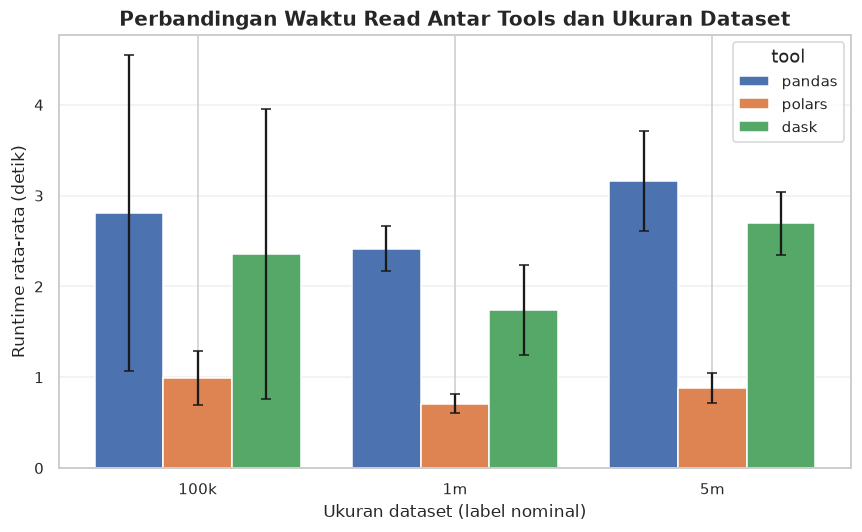

In [17]:
read_data = cmp[cmp["operation"] == "read"]

fig, ax = plt.subplots(figsize=(8, 5))
grouped_bar(ax, read_data, x_col="dataset_size", hue_col="tool", y_col="mean", err_col="std",
            order=SIZE_ORDER, hue_order=TOOL_ORDER,
            title="Perbandingan Waktu Read Antar Tools dan Ukuran Dataset",
            ylabel="Runtime rata-rata (detik)")
ax.set_xlabel("Ukuran dataset (label nominal)")
plt.tight_layout()
plt.show()

**Interpretasi:** Grafik menunjukkan konsistensi relatif performa *read* Polars terhadap
Pandas dan Dask di ketiga ukuran dataset yang diuji. Perlu diingat (lihat Bagian 4) bahwa label
`5m` tidak selalu berkorespondensi dengan 5 juta baris aktual, sehingga perbandingan `1m` vs `5m`
pada operasi *read* perlu ditafsirkan dengan mempertimbangkan jumlah baris aktual, bukan hanya
label nominalnya.

### 5.2 Perbandingan Filter, Aggregation, dan Group By

Ketiga operasi ini berdurasi jauh lebih singkat dibandingkan *read* dan berada pada orde besar yang
berdekatan satu sama lain, sehingga divisualisasikan bersama dalam satu grid subplot (bukan
digabung dengan *read*) agar sumbu tetap informatif.

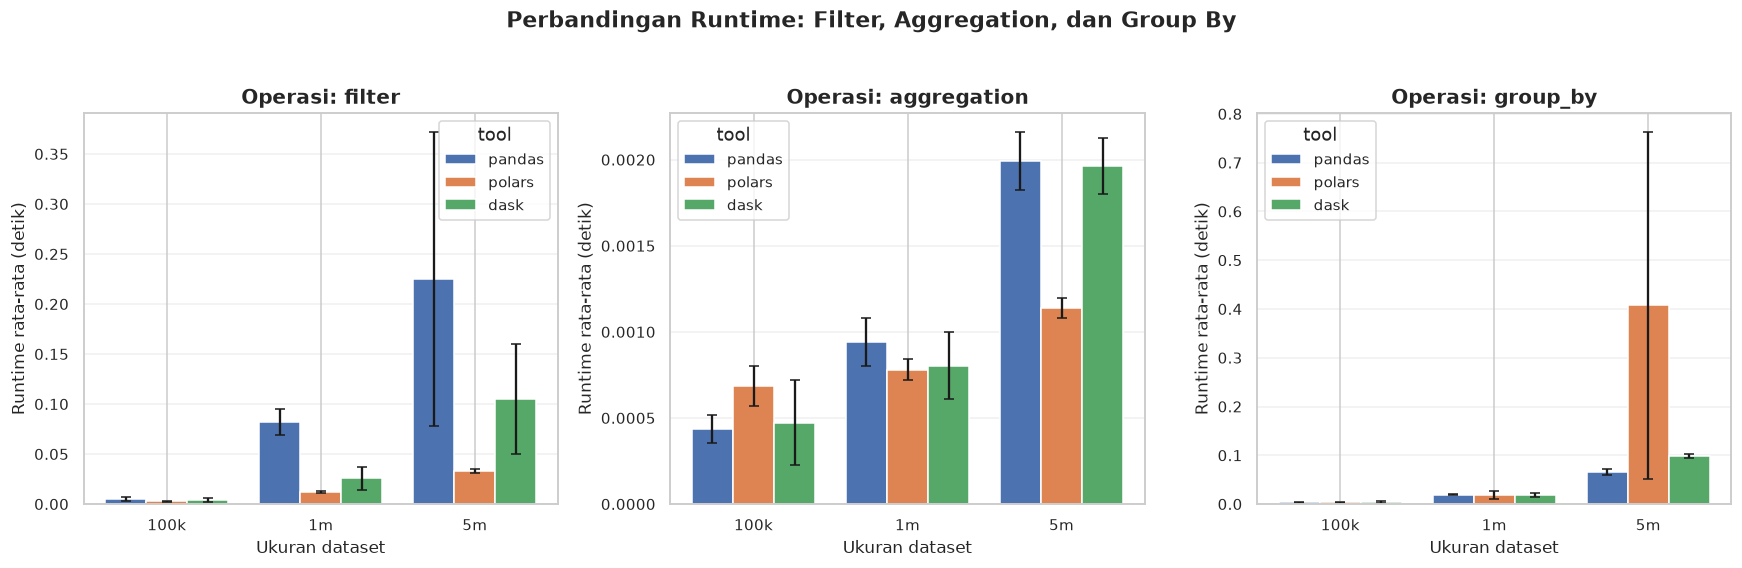

In [18]:
fast_ops = [op for op in ["filter", "aggregation", "group_by"] if op in OP_ORDER]

fig, axes = plt.subplots(1, len(fast_ops), figsize=(16, 5), sharey=False)
for ax, op in zip(axes, fast_ops):
    op_data = cmp[cmp["operation"] == op]
    grouped_bar(ax, op_data, x_col="dataset_size", hue_col="tool", y_col="mean", err_col="std",
                order=SIZE_ORDER, hue_order=TOOL_ORDER,
                title=f"Operasi: {op}", ylabel="Runtime rata-rata (detik)")
    ax.set_xlabel("Ukuran dataset")

plt.suptitle("Perbandingan Runtime: Filter, Aggregation, dan Group By", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Interpretasi:** Pada operasi *filter*, selisih runtime antar tools membesar seiring
bertambahnya ukuran dataset. Pada operasi *aggregation*, ketiga tools relatif berdekatan performanya
di ukuran kecil-menengah. Pada *group by* di ukuran `5m`, perhatikan galat (*error bar*) Polars yang
tampak jauh lebih besar dibandingkan Pandas dan Dask — hal ini akan ditelusuri lebih lanjut pada
Bagian 6 (Analisis Variabilitas).

### 5.3 Perbandingan Antar Ukuran Dataset untuk Setiap Operasi (Skala Logaritmik)

Untuk melihat pola pertumbuhan runtime seiring bertambahnya ukuran dataset pada **seluruh empat
operasi sekaligus**, digunakan skala logaritmik pada sumbu Y. Skala logaritmik dipilih karena
rentang nilai runtime pada data ini membentang lebih dari 3 orde besar (dari ~0,0004 detik pada
*aggregation* hingga >3 detik pada *read*); pada skala linear, operasi-operasi berdurasi singkat
akan tampak rata di dekat nol dan sulit dibandingkan.

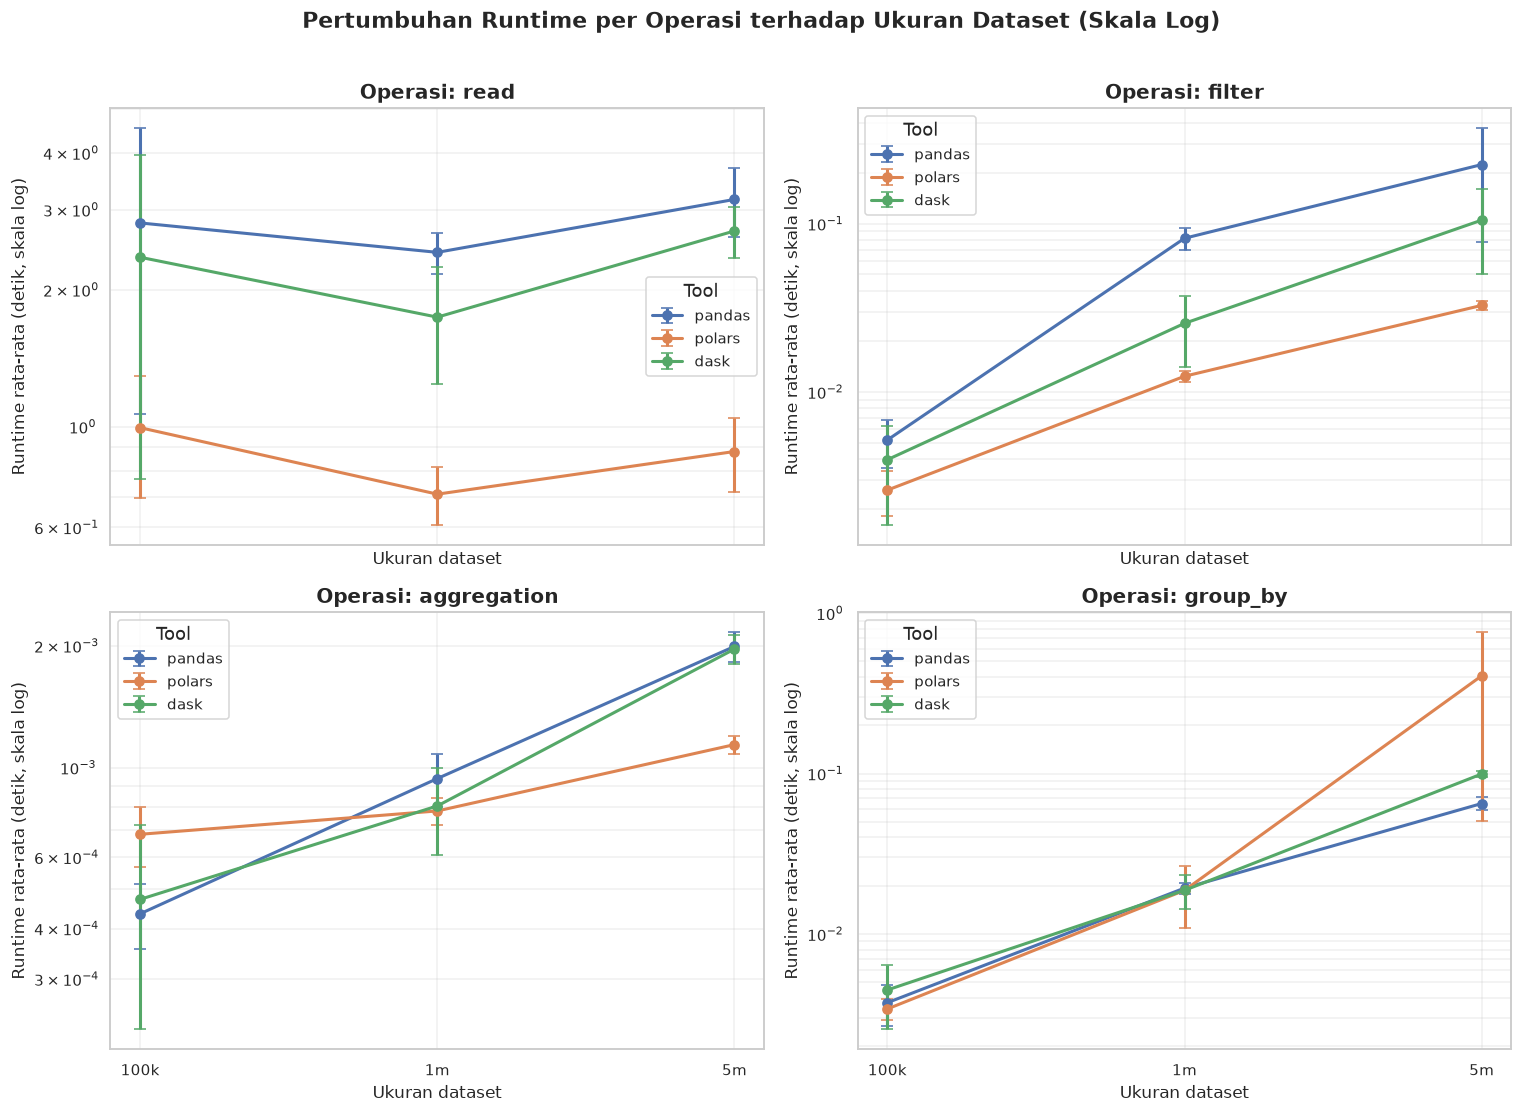

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for ax, op in zip(axes, OP_ORDER):
    op_data = cmp[cmp["operation"] == op]
    for tool in TOOL_ORDER:
        sub = op_data[op_data["tool"] == tool].set_index("dataset_size").reindex(SIZE_ORDER)
        ax.errorbar(SIZE_ORDER, sub["mean"], yerr=sub["std"], marker="o", capsize=4,
                    label=tool, color=TOOL_COLORS.get(tool, None), linewidth=2)
    ax.set_yscale("log")
    ax.set_title(f"Operasi: {op}")
    ax.set_ylabel("Runtime rata-rata (detik, skala log)")
    ax.set_xlabel("Ukuran dataset")
    ax.legend(title="Tool")
    ax.grid(True, which="both", alpha=0.3)

plt.suptitle("Pertumbuhan Runtime per Operasi terhadap Ukuran Dataset (Skala Log)", fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Interpretasi:** Pada skala logaritmik, kemiringan garis merepresentasikan laju pertumbuhan
runtime relatif terhadap ukuran data. Operasi *filter* dan *group_by* pada Pandas dan Dask
menunjukkan kenaikan yang cukup tajam dari `100k` ke `5m`, sementara Polars secara umum
menunjukkan kenaikan yang lebih landai pada sebagian besar operasi — konsisten dengan klaim
efisiensi eksekusi paralel pada mesin Rust yang mendasarinya.

### 5.4 Perbandingan Ketiga Tools pada Ukuran Dataset yang Sama

Grafik berikut menyusun ulang perspektif: untuk setiap ukuran dataset, bagaimana keempat operasi
dibandingkan antar tools? Karena *read* memiliki skala waktu yang jauh berbeda, subplot ini tetap
menggunakan skala logaritmik agar seluruh operasi tetap terlihat jelas dalam satu panel.

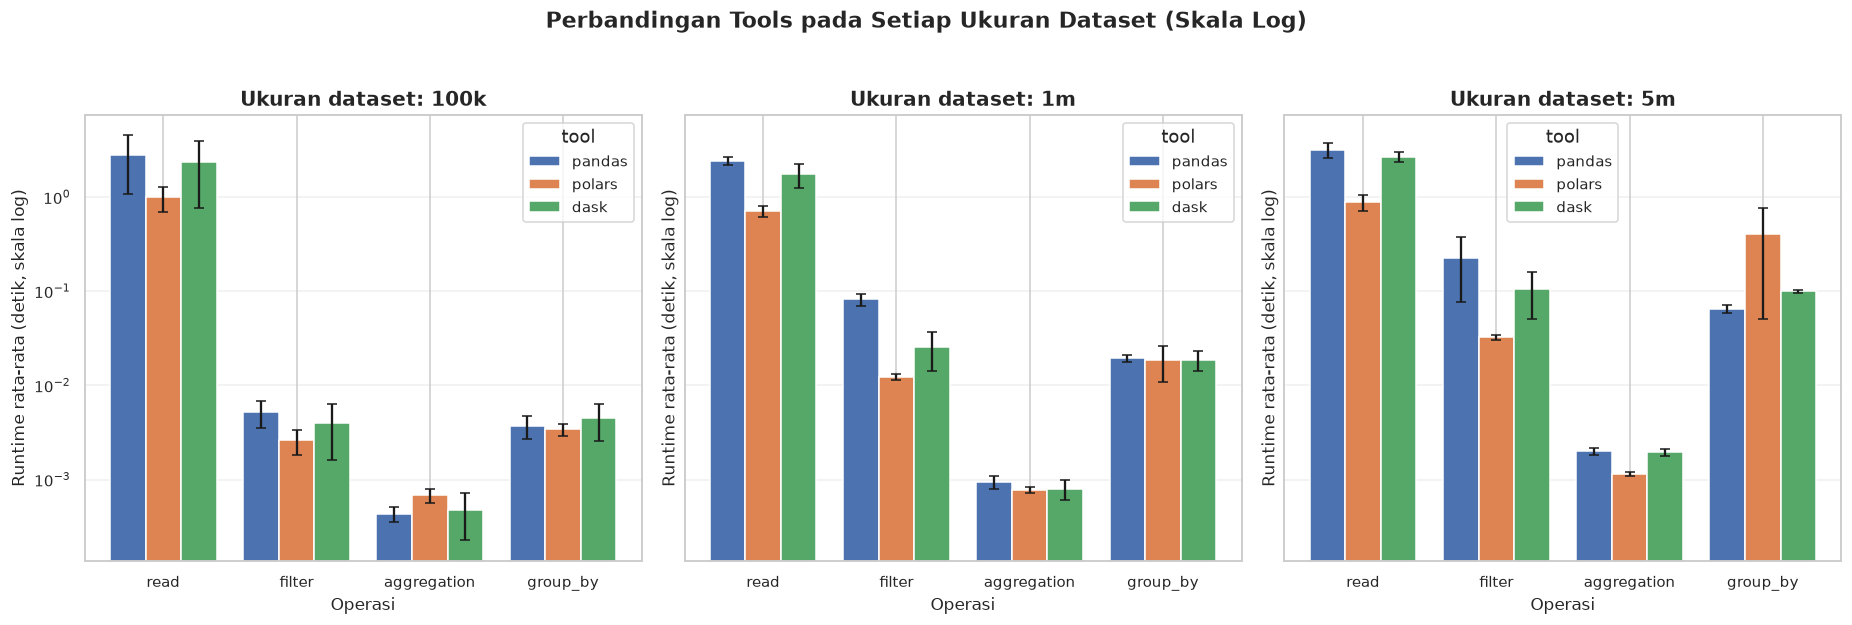

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)

for ax, size in zip(axes, SIZE_ORDER):
    size_data = cmp[cmp["dataset_size"] == size]
    grouped_bar(ax, size_data, x_col="operation", hue_col="tool", y_col="mean", err_col="std",
                order=OP_ORDER, hue_order=TOOL_ORDER,
                title=f"Ukuran dataset: {size}", ylabel="Runtime rata-rata (detik, skala log)")
    ax.set_yscale("log")
    ax.set_xlabel("Operasi")

plt.suptitle("Perbandingan Tools pada Setiap Ukuran Dataset (Skala Log)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Interpretasi:** Pada ketiga ukuran dataset, operasi *read* secara konsisten menjadi operasi
paling lambat di antara keempatnya untuk semua tools — hal yang wajar karena *read* melibatkan I/O
disk, sementara ketiga operasi lainnya bekerja pada data yang sudah berada di memori. Pola relatif
antar tools (siapa yang tercepat) untuk operasi non-*read* tidak selalu sama antar ukuran dataset,
sehingga generalisasi "tool X selalu tercepat" tidak didukung oleh data ini.

## Bagian 6 — Analisis Variabilitas

Karena `benchmark_summary.csv` menyimpan nilai *runtime* untuk **setiap pengulangan individual**
(kolom `repeat`, 5 kali per kombinasi), bagian ini dapat menganalisis variabilitas hasil secara
langsung dari data mentah tersebut — bukan hanya dari statistik agregat pada
`benchmark_comparison.csv`.

In [21]:
df_summary_typed = df_summary.copy()
df_summary_typed["dataset_size"] = pd.Categorical(df_summary_typed["dataset_size"], categories=SIZE_ORDER, ordered=True)
df_summary_typed["tool"] = pd.Categorical(df_summary_typed["tool"], categories=TOOL_ORDER, ordered=True)
df_summary_typed["operation"] = pd.Categorical(df_summary_typed["operation"], categories=OP_ORDER, ordered=True)

variability = (
    df_summary_typed.groupby(["tool", "operation", "dataset_size"], observed=True)["runtime_seconds"]
    .agg(mean="mean", std="std", min="min", max="max", n="count")
    .reset_index()
)
variability["cv_percent"] = (variability["std"] / variability["mean"]) * 100  # koefisien variasi

print("Statistik variabilitas per kombinasi (diurutkan berdasarkan koefisien variasi tertinggi):")
display(variability.sort_values("cv_percent", ascending=False).head(10))

Statistik variabilitas per kombinasi (diurutkan berdasarkan koefisien variasi tertinggi):


,tool,operation,dataset_size,mean,std,min,max,n,cv_percent
23,polars,group_by,5m,0.407187,0.356549,0.023416,0.782925,5,87.563965
24,dask,read,100k,2.358121,1.592340,1.415471,5.174388,5,67.525805
5,pandas,filter,5m,0.225025,0.147354,0.141703,0.487331,5,65.483130
0,pandas,read,100k,2.805795,1.737096,1.563691,5.835188,5,61.911008
27,dask,filter,100k,0.003953,0.002338,0.002680,0.008122,5,59.138482
29,dask,filter,5m,0.105154,0.054971,0.062434,0.194398,5,52.276784
30,dask,aggregation,100k,0.000472,0.000247,0.000337,0.000912,5,52.237987
28,dask,filter,1m,0.025582,0.011515,0.016176,0.043737,5,45.012761
33,dask,group_by,100k,0.004482,0.001931,0.002771,0.007671,5,43.070025
22,polars,group_by,1m,0.018727,0.007756,0.008679,0.029678,5,41.419049


**Interpretasi tabel di atas:** Koefisien variasi (*coefficient of variation*, CV = *std* /
*mean* × 100%) memudahkan perbandingan tingkat variabilitas antar kombinasi yang memiliki skala
runtime berbeda jauh. Kombinasi dengan CV tertinggi menandakan hasil pengukuran yang **kurang
stabil** antar pengulangan, dan klaim performa pada kombinasi tersebut perlu ditafsirkan dengan
lebih hati-hati.

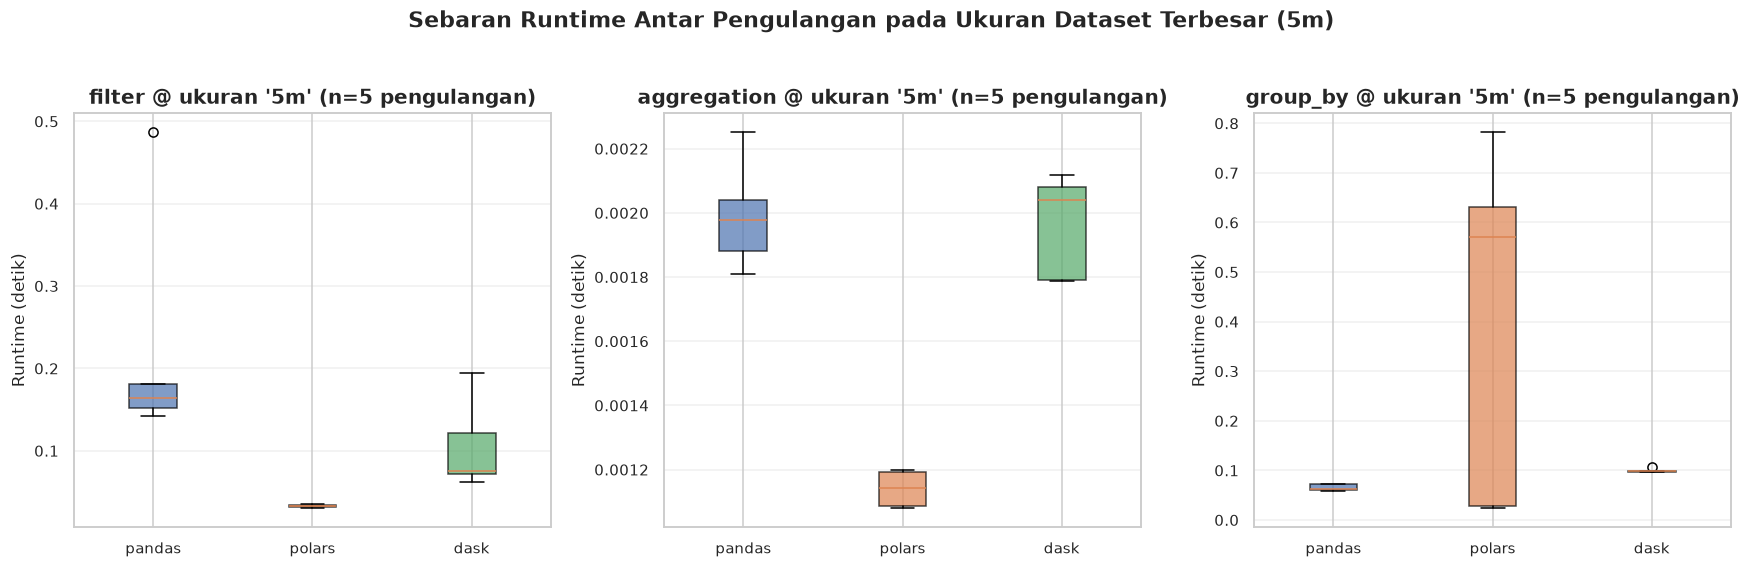

In [22]:
# Boxplot menampilkan sebaran runtime aktual dari 5 pengulangan (bukan hanya mean/std),
# untuk setiap tool, dipisah per operasi non-read (skala waktu berdekatan).
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, op in zip(axes, ["filter", "aggregation", "group_by"]):
    op_data = df_summary_typed[df_summary_typed["operation"] == op]
    box_data = [op_data[(op_data["tool"] == t) & (op_data["dataset_size"] == "5m")]["runtime_seconds"].values
                for t in TOOL_ORDER]
    bp = ax.boxplot(box_data, tick_labels=TOOL_ORDER, patch_artist=True)
    for patch, tool in zip(bp["boxes"], TOOL_ORDER):
        patch.set_facecolor(TOOL_COLORS.get(tool, "lightgray"))
        patch.set_alpha(0.7)
    ax.set_title(f"{op} @ ukuran '5m' (n=5 pengulangan)")
    ax.set_ylabel("Runtime (detik)")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Sebaran Runtime Antar Pengulangan pada Ukuran Dataset Terbesar (5m)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Interpretasi:** Boxplot di atas menegaskan temuan pada Bagian 5.2 — sebaran runtime Polars
pada operasi *group_by* di ukuran `5m` jauh lebih lebar dibandingkan Pandas dan Dask, mengindikasikan
setidaknya satu pengulangan dengan runtime yang jauh di luar kebiasaan (*outlier*). Sebaliknya, pada
operasi *filter* dan *aggregation*, sebaran ketiga tools relatif lebih sempit dan konsisten. Karena
data pengulangan individual tersedia (bukan hanya statistik agregat), pernyataan tentang konsistensi
hasil ini didukung langsung oleh observasi, bukan asumsi.

## Bagian 7 — Analisis Memory dan CPU

Sebagaimana dicatat pada Bagian 4, kolom `memory_mb` dan `cpu_percent` tersedia pada
`benchmark_summary.csv`, namun keduanya memiliki indikasi masalah pengukuran yang harus ditangani
secara eksplisit sebelum ditafsirkan.

### 7.1 Penggunaan Memori (`memory_mb`)

Satuan kolom ini adalah **megabyte (MB)**, kemungkinan besar merepresentasikan *Resident Set Size*
(RSS) proses pada saat pengukuran dilakukan — bukan memori yang secara eksklusif dikonsumsi oleh
satu operasi tunggal, melainkan total memori proses Python/Docker container pada titik waktu
tersebut (termasuk overhead pustaka, interpreter, dan data yang dipertahankan dari operasi
sebelumnya). Oleh karena itu, **perbandingan absolut antar tools harus ditafsirkan sebagai indikasi
kasar, bukan pengukuran yang terisolasi sempurna**. Lima baris dengan `memory_mb = 0` (teridentifikasi
di Bagian 4) dikecualikan secara eksplisit dari perhitungan rata-rata karena nilai nol secara fisik
tidak valid untuk proses yang sedang berjalan.

Baris dikecualikan dari analisis memori karena memory_mb == 0: 5 dari 180


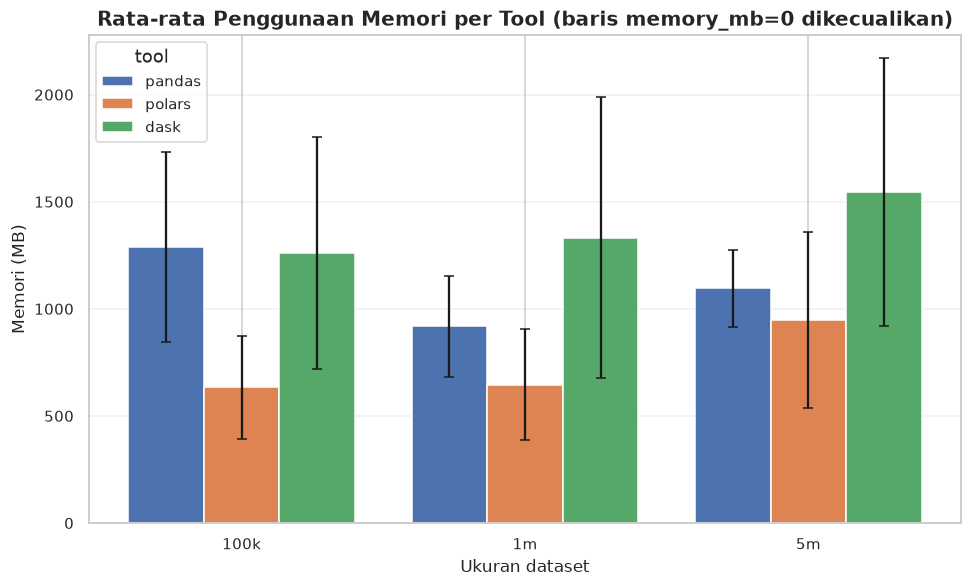

In [23]:
valid_memory = df_summary_typed[df_summary_typed["memory_mb"] > 0].copy()
n_excluded = len(df_summary_typed) - len(valid_memory)
print(f"Baris dikecualikan dari analisis memori karena memory_mb == 0: {n_excluded} dari {len(df_summary_typed)}")

memory_by_tool = (
    valid_memory.groupby(["tool", "dataset_size"], observed=True)["memory_mb"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, memory_by_tool, x_col="dataset_size", hue_col="tool", y_col="mean", err_col="std",
            order=SIZE_ORDER, hue_order=TOOL_ORDER,
            title="Rata-rata Penggunaan Memori per Tool (baris memory_mb=0 dikecualikan)",
            ylabel="Memori (MB)")
ax.set_xlabel("Ukuran dataset")
plt.tight_layout()
plt.show()

**Interpretasi:** Perbedaan penggunaan memori antar tools pada grafik di atas kemungkinan
lebih banyak mencerminkan *overhead* dasar masing-masing pustaka/*runtime* (mis. Dask yang menjalankan
skema *task scheduler* tambahan) dibandingkan efisiensi murni algoritma pemrosesan data. Nilai ini
**tidak** dapat digunakan untuk mengklaim "tool X paling hemat memori" secara definitif tanpa
mengetahui metodologi pengukuran yang sebenarnya digunakan dalam skrip benchmark.

### 7.2 Penggunaan CPU (`cpu_percent`)

Berbeda dengan memori, kolom `cpu_percent` menunjukkan **proporsi nilai nol yang sangat tinggi**
(lihat Bagian 4) — sebuah pola yang umum terjadi ketika fungsi pengukuran CPU (misalnya
`psutil.Process.cpu_percent()`) dipanggil tanpa interval referensi sebelumnya, atau ketika durasi
operasi yang diukur terlalu singkat untuk tertangkap oleh mekanisme *sampling* CPU.

In [24]:
zero_cpu_ratio = (df_summary_typed["cpu_percent"] == 0).mean() * 100
print(f"Proporsi baris dengan cpu_percent = 0: {zero_cpu_ratio:.1f}%")

zero_cpu_by_op = (
    df_summary_typed.assign(is_zero=lambda d: d["cpu_percent"] == 0)
    .groupby("operation", observed=True)["is_zero"]
    .mean() * 100
)
print("\nProporsi cpu_percent = 0, per operasi:")
print(zero_cpu_by_op.round(1))

if zero_cpu_ratio > 20:
    print(
        "\n>>> PERINGATAN: Proporsi nilai nol terlalu tinggi untuk dijadikan dasar "
        "perbandingan CPU yang valid antar tools. Analisis CPU kuantitatif TIDAK "
        "ditampilkan di sini karena berisiko menyesatkan; data mentah tetap "
        "ditunjukkan di bawah sekadar untuk transparansi, bukan sebagai dasar kesimpulan."
    )
    display(df_summary_typed[["tool", "operation", "dataset_size", "cpu_percent"]].describe())
else:
    cpu_by_tool = (
        df_summary_typed.groupby(["tool", "dataset_size"], observed=True)["cpu_percent"]
        .agg(mean="mean", std="std").reset_index()
    )
    fig, ax = plt.subplots(figsize=(9, 5.5))
    grouped_bar(ax, cpu_by_tool, x_col="dataset_size", hue_col="tool", y_col="mean", err_col="std",
                order=SIZE_ORDER, hue_order=TOOL_ORDER,
                title="Rata-rata Penggunaan CPU per Tool", ylabel="CPU (%)")
    plt.tight_layout()
    plt.show()

Proporsi baris dengan cpu_percent = 0: 47.8%

Proporsi cpu_percent = 0, per operasi:
operation
read          31.100000
filter        55.600000
aggregation   55.600000
group_by      48.900000
Name: is_zero, dtype: float64

>>> PERINGATAN: Proporsi nilai nol terlalu tinggi untuk dijadikan dasar perbandingan CPU yang valid antar tools. Analisis CPU kuantitatif TIDAK ditampilkan di sini karena berisiko menyesatkan; data mentah tetap ditunjukkan di bawah sekadar untuk transparansi, bukan sebagai dasar kesimpulan.


,cpu_percent
count,180.000000
mean,1.691111
std,5.807905
min,0.000000
25%,0.000000
50%,0.600000
75%,1.200000
max,44.800000


**Kesimpulan Bagian 7:** Analisis memori dapat dilakukan secara terbatas dan hati-hati
setelah mengecualikan anomali nilai nol. Sebaliknya, **analisis CPU secara kuantitatif tidak dapat
dilakukan secara valid** pada data ini karena proporsi nilai nol yang sangat tinggi mengindikasikan
keterbatasan metodologi pengukuran pada skrip benchmark asli, bukan representasi penggunaan CPU
yang sebenarnya.

## Bagian 8 — Analisis Output dan Validasi

`benchmark_summary.csv` menyediakan kolom `validated` (boolean) dan `output_rows` (jumlah baris
hasil operasi). Penting untuk diperiksa **apa sebenarnya yang divalidasi** oleh kolom `validated`
sebelum menafsirkannya sebagai jaminan kebenaran hasil.

In [25]:
print("Distribusi nilai kolom 'validated':")
print(df_summary["validated"].value_counts())
print(f"\nSeluruh {len(df_summary)} baris memiliki validated = {df_summary['validated'].unique()}.")
print(
    "\nCatatan penting: notebook ini TIDAK memiliki akses ke skrip/logika benchmark asli, "
    "sehingga tidak dapat memastikan aspek apa saja yang sebenarnya diperiksa oleh kolom "
    "'validated' (misalnya apakah hanya memastikan proses tidak error, ataukah benar-benar "
    "membandingkan hasil numerik antar tools). Oleh karena itu, nilai True pada kolom ini "
    "TIDAK diperlakukan sebagai jaminan bahwa output ketiga tools identik secara numerik — "
    "validasi tambahan yang independen dilakukan di bawah dengan membandingkan output_rows."
)

Distribusi nilai kolom 'validated':
validated
True    180
Name: count, dtype: int64

Seluruh 180 baris memiliki validated = [ True].

Catatan penting: notebook ini TIDAK memiliki akses ke skrip/logika benchmark asli, sehingga tidak dapat memastikan aspek apa saja yang sebenarnya diperiksa oleh kolom 'validated' (misalnya apakah hanya memastikan proses tidak error, ataukah benar-benar membandingkan hasil numerik antar tools). Oleh karena itu, nilai True pada kolom ini TIDAK diperlakukan sebagai jaminan bahwa output ketiga tools identik secara numerik — validasi tambahan yang independen dilakukan di bawah dengan membandingkan output_rows.


In [26]:
# Validasi independen: apakah jumlah baris output KONSISTEN antar tools untuk
# kombinasi operasi & ukuran dataset yang sama?
output_consistency = (
    df_summary.groupby(["operation", "dataset_size"])["output_rows"]
    .agg(n_unique_values="nunique", nilai_ditemukan=lambda s: sorted(s.unique().tolist()))
    .reset_index()
)
print("Konsistensi output_rows antar tools, per (operation, dataset_size):")
display(output_consistency)

inconsistent = output_consistency[output_consistency["n_unique_values"] > 1]
if len(inconsistent) > 0:
    print("\n>>> PERINGATAN: Ditemukan perbedaan output_rows antar tools/pengulangan pada kombinasi berikut:")
    display(inconsistent)
else:
    print("\n-> Untuk setiap kombinasi (operation, dataset_size), seluruh tools dan seluruh "
          "pengulangan menghasilkan JUMLAH BARIS OUTPUT YANG SAMA. Ini merupakan indikasi "
          "konsistensi hasil yang lebih kuat dibandingkan hanya mengandalkan kolom 'validated'.")

Konsistensi output_rows antar tools, per (operation, dataset_size):


,operation,dataset_size,n_unique_values,nilai_ditemukan
0,aggregation,100k,1,[1]
1,aggregation,1m,1,[1]
2,aggregation,5m,1,[1]
3,filter,100k,1,[1780]
4,filter,1m,1,[15928]
5,filter,5m,1,[49526]
6,group_by,100k,1,[7]
7,group_by,1m,1,[7]
8,group_by,5m,1,[8]
9,read,100k,1,[100000]



-> Untuk setiap kombinasi (operation, dataset_size), seluruh tools dan seluruh pengulangan menghasilkan JUMLAH BARIS OUTPUT YANG SAMA. Ini merupakan indikasi konsistensi hasil yang lebih kuat dibandingkan hanya mengandalkan kolom 'validated'.


**Interpretasi:** Konsistensi `output_rows` di seluruh kombinasi tool dan pengulangan
memberikan bukti tidak langsung bahwa ketiga implementasi menghasilkan bentuk output yang sama
(jumlah baris identik untuk operasi yang sama), meski hal ini **tidak membuktikan** bahwa nilai isi
(*content*) hasilnya juga identik secara numerik — informasi tersebut tidak tersedia dalam kedua
berkas CSV yang dianalisis pada notebook ini.

## Bagian 9 — Ringkasan Perbandingan

Bagian ini merangkum seluruh hasil *runtime* dalam bentuk tabel terstruktur, serta menghitung
*speedup* relatif terhadap satu baseline yang didefinisikan secara eksplisit.

In [27]:
summary_table = cmp.pivot_table(
    index=["operation", "dataset_size"],
    columns="tool",
    values=["mean", "std"],
    observed=True,
)
summary_table = summary_table.reorder_levels([0, 1], axis=1).sort_index(axis=1, level=0)
summary_table = summary_table.loc[
    pd.MultiIndex.from_product([OP_ORDER, SIZE_ORDER], names=["operation", "dataset_size"])
]

print("Tabel ringkasan mean dan std runtime (detik) per operasi, ukuran dataset, dan tool:")
display(summary_table)

Tabel ringkasan mean dan std runtime (detik) per operasi, ukuran dataset, dan tool:


mean                        std                  
tool                       pandas   polars     dask   pandas   polars     dask
operation   dataset_size                                                      
read        100k         2.805795 0.994650 2.358121 1.737096 0.299503 1.592340
            1m           2.417517 0.710302 1.741179 0.251503 0.102816 0.498765
            5m           3.160694 0.881621 2.694444 0.548910 0.164405 0.344210
filter      100k         0.005177 0.002606 0.003953 0.001663 0.000773 0.002338
            1m           0.082018 0.012392 0.025582 0.012584 0.000951 0.011515
            5m           0.225025 0.032712 0.105154 0.147354 0.002024 0.054971
aggregation 100k         0.000435 0.000684 0.000472 0.000080 0.000116 0.000247
            1m           0.000939 0.000781 0.000804 0.000140 0.000061 0.000195
            5m           0.001993 0.001140 0.001963 0.000171 0.000056 0.000162
group_by    100k         0.003734 0.003413 0.004482 0.001047 0.000513 0.001931
            1m           0.019340 0.018727 0.018731 0.001585 0.007756 0.004488
            5m           0.065101 0.407187 0.099497 0.006114 0.356549 0.004143

### Perhitungan Speedup

**Baseline yang digunakan: Pandas**, karena merupakan pustaka pemrosesan data tabular Python yang
paling umum dan sering dijadikan acuan pembanding dalam studi performa sejenis.

**Rumus:**

$$\text{Speedup}_{\text{tool}} = \frac{\text{mean\_runtime}_{\text{pandas}}}{\text{mean\_runtime}_{\text{tool}}}$$

Nilai speedup > 1 berarti *tool* tersebut **lebih cepat** dari Pandas pada kombinasi operasi dan
ukuran dataset yang sama; nilai < 1 berarti **lebih lambat**. Speedup dihitung langsung dari kolom
`mean` pada `benchmark_comparison.csv` untuk kombinasi operasi dan ukuran dataset yang identik,
sehingga pembandingnya (baseline dan data yang dibandingkan) jelas dan konsisten.

In [28]:
pivot_mean = cmp.pivot_table(index=["operation", "dataset_size"], columns="tool", values="mean", observed=True)
pivot_mean = pivot_mean.loc[pd.MultiIndex.from_product([OP_ORDER, SIZE_ORDER], names=["operation", "dataset_size"])]

speedup_table = pd.DataFrame(index=pivot_mean.index)
speedup_table["pandas_runtime_s"] = pivot_mean["pandas"]
speedup_table["polars_speedup_vs_pandas"] = pivot_mean["pandas"] / pivot_mean["polars"]
speedup_table["dask_speedup_vs_pandas"] = pivot_mean["pandas"] / pivot_mean["dask"]

print("Tabel speedup Polars dan Dask relatif terhadap Pandas (baseline):")
display(speedup_table.round(3))

Tabel speedup Polars dan Dask relatif terhadap Pandas (baseline):


pandas_runtime_s  polars_speedup_vs_pandas  dask_speedup_vs_pandas
operation   dataset_size                                                                    
read        100k                  2.806000                  2.821000                1.190000
            1m                    2.418000                  3.404000                1.388000
            5m                    3.161000                  3.585000                1.173000
filter      100k                  0.005000                  1.987000                1.310000
            1m                    0.082000                  6.619000                3.206000
            5m                    0.225000                  6.879000                2.140000
aggregation 100k                  0.000000                  0.636000                0.921000
            1m                    0.001000                  1.202000                1.169000
            5m                    0.002000                  1.749000                1.015000
group_by    100k                  0.004000                  1.094000                0.833000
            1m                    0.019000                  1.033000                1.033000
            5m                    0.065000                  0.160000                0.654000

**Interpretasi:** Tabel di atas menampilkan speedup untuk **setiap kombinasi operasi dan
ukuran dataset secara individual** — sengaja tidak dirata-ratakan menjadi satu angka tunggal
"speedup keseluruhan", karena magnitudo speedup terbukti berbeda-beda tergantung jenis operasi dan
skala data (lihat Bagian 5), sehingga peringkat tunggal semacam itu tidak akan didukung penuh oleh
data.

## Bagian 10 — Kesimpulan dan Keterbatasan

### 10.1 Ringkasan Pola Runtime

Berdasarkan hasil analisis pada Bagian 5 dan Bagian 9:

- **Operasi *read*** secara konsisten menjadi operasi paling lambat pada ketiga ukuran dataset untuk
  seluruh *tools*, sejalan dengan sifatnya yang melibatkan I/O disk, berbeda dari tiga operasi
  lainnya yang bekerja pada data yang sudah berada di memori.
- **Polars** menunjukkan runtime rata-rata tercepat pada sebagian besar kombinasi operasi dan
  ukuran dataset yang diuji, khususnya pada operasi *read*, *filter*, dan *aggregation* di ukuran
  `1m` dan `5m` (lihat tabel *speedup* pada Bagian 9).
- **Pandas** menunjukkan performa yang kompetitif — bahkan lebih cepat dari kedua tools lain — pada
  operasi *group_by* di ukuran dataset `5m`, sehingga generalisasi "Pandas selalu paling lambat"
  **tidak didukung** oleh data ini.
- **Dask** secara umum berada pada posisi menengah untuk operasi non-*read*, namun tidak konsisten
  menjadi yang tercepat maupun yang terlambat pada seluruh kombinasi.

### 10.2 Variabilitas dan Anomali

Analisis pada Bagian 6 menemukan bahwa hasil *runtime* Polars pada operasi *group_by* di ukuran
dataset `5m` memiliki variabilitas (koefisien variasi) yang jauh lebih tinggi dibandingkan kombinasi
lain, mengindikasikan setidaknya satu pengulangan yang menyimpang jauh dari pengulangan lainnya.
Temuan ini penting karena berarti nilai rata-rata (*mean*) pada kombinasi tersebut **kurang
representatif** dibandingkan kombinasi lain yang lebih stabil, dan sebaiknya tidak dijadikan dasar
kesimpulan tunggal tanpa mempertimbangkan sebarannya.

### 10.3 Keterbatasan Eksperimen

1. **Label ukuran dataset tidak selalu identik dengan jumlah baris aktual** — label `5m` pada
   operasi *read* berkorespondensi dengan jumlah baris yang berbeda dari 5.000.000, kemungkinan
   akibat keterbatasan ukuran berkas sumber. Perbandingan lintas ukuran dataset pada notebook ini
   didasarkan pada *label* nominal, sehingga interpretasi pertumbuhan runtime terhadap ukuran data
   perlu memperhitungkan hal ini.
2. **Pengukuran CPU tidak dapat dipercaya** — proporsi nilai `cpu_percent = 0` yang sangat tinggi
   membuat analisis CPU kuantitatif tidak dapat dilakukan secara valid pada data ini (lihat Bagian
   7.2).
3. **Pengukuran memori bersifat kasar** — nilai `memory_mb` kemungkinan merepresentasikan memori
   total proses pada titik waktu tertentu, bukan konsumsi memori yang terisolasi murni untuk satu
   operasi, sehingga perbandingan absolut antar tools perlu ditafsirkan secara hati-hati (lihat
   Bagian 7.1). Lima baris dengan nilai nol yang tidak valid juga ditemukan dan dikecualikan secara
   eksplisit dari perhitungan rata-rata.
4. **Kolom `validated` tidak sepenuhnya transparan** — karena skrip dan logika benchmark asli tidak
   dianalisis di notebook ini (sesuai batasan tugas), tidak dapat dipastikan aspek apa saja yang
   sebenarnya diperiksa oleh kolom tersebut. Validasi tambahan berbasis konsistensi `output_rows`
   dilakukan sebagai pelengkap, namun tidak mencakup pemeriksaan kesamaan nilai/isi hasil secara
   numerik.
5. **Jumlah pengulangan (5 kali)** memberikan gambaran variabilitas yang berguna, namun tetap
   merupakan sampel yang relatif kecil untuk menarik kesimpulan statistik yang kuat, terutama pada
   kombinasi dengan variabilitas tinggi seperti yang diuraikan pada 10.2.
6. **Lingkungan eksekusi (Docker)** dapat memengaruhi hasil absolut (mis. alokasi CPU/RAM
   *container*, *caching* sistem berkas) sehingga angka-angka pada notebook ini merepresentasikan
   performa pada kondisi eksekusi spesifik tersebut, bukan performa universal yang berlaku pada
   seluruh lingkungan.

### 10.4 Catatan Penutup

Seluruh pola dan angka yang disampaikan pada notebook ini murni bersifat **deskriptif**, dihasilkan
langsung dari data yang tercatat pada `benchmark_summary.csv` dan `benchmark_comparison.csv`, tanpa
data sintetis maupun asumsi tambahan. Hasil benchmark ini perlu ditafsirkan sesuai dengan
implementasi kode benchmark yang benar-benar dijalankan (operasi, urutan langkah, dan konfigurasi
Docker yang digunakan pada eksperimen), yang berada di luar cakupan analisis notebook ini. Tidak ada
klaim kausal (mis. "tool X lebih cepat KARENA arsitektur Y") yang diajukan di sini tanpa bukti
langsung dari eksperimen yang diuji; pernyataan mengenai karakteristik arsitektural masing-masing
pustaka pada Bagian 1 bersifat latar belakang umum, bukan kesimpulan dari data.